# DATA PREPARATION

## Pengembangan Aplikasi Pengelolaan dan Pemantauan Stok Harian Terintegrasi pada UMKM ROKKUS Mardani Raya

**Program:** Asah 2026 – Data Science Specialist  
**ID Tim Capstone:** A26-CS159  
**Nama UMKM:** ROKKUS Mardani Raya  
**Periode Data:** 1–30 September 2026  
**Jumlah Produk:** 29 produk  
**Jumlah Transaksi:** 300 transaksi

### Anggota Tim

| No. | Nama Lengkap | Learning Path / Role |
|---|---|---|
| 1 | Aini Tri Apriyani | Data Science Specialist |
| 2 | Muhammad Bintang Pirgiawan | Data Science Specialist |
| 3 | Callysta Azkya Nayla Pranandita | Full Stack Developer |
| 4 | Falah Zahran Rangkuti | Full Stack Developer |
| 5 | Husain | Next Gen AI Engineer |
| 6 | Danendra Mahardika Putra Utama | Next Gen AI Engineer |

## 1. Setup Direktori dan Library

Menyiapkan direktori kerja lokal Colab serta library untuk pengolahan data. Seluruh file proyek disimpan menggunakan path relatif agar struktur folder konsisten.

In [16]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

for folder in ["data/raw", "data/processed", "outputs"]:
    os.makedirs(folder, exist_ok=True)

np.random.seed(42)
print("Direktori proyek siap digunakan.")

Direktori proyek siap digunakan.


## 2. Pembuatan Master Data, Stok Awal, dan Transaksi

Data berikut merupakan data sintetis untuk simulasi kebutuhan sistem ROKKUS, bukan catatan transaksi aktual UMKM.

In [17]:
import pandas as pd

# Master Data Produk ROKKUS
data_produk = [
    # Roti Manis
    ["PR001", "Lotus Biscoff", "Roti Manis", 18000],
    ["PR002", "Coklat Keju", "Roti Manis", 14000],
    ["PR003", "Coklat Kacang", "Roti Manis", 15000],
    ["PR004", "Nutella Keju", "Roti Manis", 18000],
    ["PR005", "Silverqueen Keju", "Roti Manis", 21000],
    ["PR006", "Ovomaltine Keju", "Roti Manis", 22000],
    ["PR007", "Srikaya", "Roti Manis", 10000],
    ["PR008", "Coklat Crunchy", "Roti Manis", 11000],
    ["PR009", "Keju", "Roti Manis", 11000],
    ["PR010", "Strawberry", "Roti Manis", 11000],
    ["PR011", "Blueberry", "Roti Manis", 11000],
    ["PR012", "Tiramisu", "Roti Manis", 11000],
    ["PR013", "Greentea", "Roti Manis", 12000],
    ["PR014", "Kacang (Peanut Butter)", "Roti Manis", 12000],
    ["PR015", "Nutella", "Roti Manis", 15000],
    ["PR016", "Silverqueen", "Roti Manis", 18000],
    ["PR017", "Ovomaltine", "Roti Manis", 19000],

    # Roti Asin
    ["PR018", "Telur Mayo", "Roti Asin", 11000],
    ["PR019", "Sosis Mayo", "Roti Asin", 13000],
    ["PR020", "Telur Sosis Mayo", "Roti Asin", 14000],
    ["PR021", "Beef Mayo", "Roti Asin", 15000],
    ["PR022", "Beef Sosis Mayo", "Roti Asin", 17000],
    ["PR023", "Telur Beef", "Roti Asin", 18000],
    ["PR024", "Double Beef", "Roti Asin", 19000],
    ["PR025", "Telur Beef Sosis", "Roti Asin", 19000],

    # Tambahan
    ["AD001", "Keju Slice", "Tambahan", 2000],
    ["AD002", "Keju Parut", "Tambahan", 3000],
    ["AD003", "Telur", "Tambahan", 3000],
    ["AD004", "Selai Lain", "Tambahan", 3000]
]

df_produk = pd.DataFrame(
    data_produk,
    columns=["product_id", "product_name", "category", "price"]
)

# Tampilkan seluruh master produk
display(df_produk)

# Periksa jumlah produk per kategori
print("Jumlah produk:", len(df_produk))
display(df_produk["category"].value_counts())

# Simpan ke CSV
df_produk.to_csv(
    "data/raw/master_produk_rokkus.csv",
    index=False
)

print("Master data produk berhasil disimpan!")


,product_id,product_name,category,price
0,PR001,Lotus Biscoff,Roti Manis,18000
1,PR002,Coklat Keju,Roti Manis,14000
2,PR003,Coklat Kacang,Roti Manis,15000
3,PR004,Nutella Keju,Roti Manis,18000
4,PR005,Silverqueen Keju,Roti Manis,21000
5,PR006,Ovomaltine Keju,Roti Manis,22000
6,PR007,Srikaya,Roti Manis,10000
7,PR008,Coklat Crunchy,Roti Manis,11000
8,PR009,Keju,Roti Manis,11000
9,PR010,Strawberry,Roti Manis,11000


Jumlah produk: 29


,count
category,
Roti Manis,17
Roti Asin,8
Tambahan,4


Master data produk berhasil disimpan!


In [18]:
import pandas as pd
import numpy as np

# Seed agar hasil simulasi konsisten setiap dijalankan
np.random.seed(42)

# Data stok awal sintetis
df_stok_awal = df_produk[["product_id", "product_name", "category"]].copy()

df_stok_awal["tanggal_stok"] = "2026-09-01"
df_stok_awal["stok_awal"] = np.random.randint(
    10, 31, size=len(df_stok_awal)
)

display(df_stok_awal)

# Simpan data
df_stok_awal.to_csv(
    "data/raw/stok_awal.csv",
    index=False
)

print("Jumlah data stok awal:", len(df_stok_awal))
print("File stok_awal.csv berhasil dibuat!")


,product_id,product_name,category,tanggal_stok,stok_awal
0,PR001,Lotus Biscoff,Roti Manis,2026-09-01,16
1,PR002,Coklat Keju,Roti Manis,2026-09-01,29
2,PR003,Coklat Kacang,Roti Manis,2026-09-01,24
3,PR004,Nutella Keju,Roti Manis,2026-09-01,20
4,PR005,Silverqueen Keju,Roti Manis,2026-09-01,17
5,PR006,Ovomaltine Keju,Roti Manis,2026-09-01,30
6,PR007,Srikaya,Roti Manis,2026-09-01,16
7,PR008,Coklat Crunchy,Roti Manis,2026-09-01,28
8,PR009,Keju,Roti Manis,2026-09-01,20
9,PR010,Strawberry,Roti Manis,2026-09-01,20


Jumlah data stok awal: 29
File stok_awal.csv berhasil dibuat!


In [19]:

# Membuat transaksi sintetis secara kronologis
# dengan memperhatikan ketersediaan stok

np.random.seed(42)

jumlah_transaksi = 300

tanggal_transaksi = pd.date_range(
    start="2026-09-01",
    end="2026-09-30",
    periods=jumlah_transaksi
)

df_transaksi = pd.DataFrame({
    "transaction_id": [
        f"TRX{i:04d}" for i in range(1, jumlah_transaksi + 1)
    ],
    "product_id": np.random.choice(
        df_produk["product_id"],
        jumlah_transaksi
    ),
    "tanggal": tanggal_transaksi,
    "jenis_transaksi": np.random.choice(
        ["MASUK", "KELUAR"],
        jumlah_transaksi,
        p=[0.35, 0.65]
    ),
    "jumlah": np.random.randint(
        1, 11, jumlah_transaksi
    )
})

df_transaksi = df_transaksi.sort_values(
    "tanggal"
).reset_index(drop=True)

stok_berjalan = dict(
    zip(
        df_stok_awal["product_id"],
        df_stok_awal["stok_awal"]
    )
)

jenis_final = []
jumlah_final = []

for _, transaksi in df_transaksi.iterrows():

    product_id = transaksi["product_id"]
    jenis = transaksi["jenis_transaksi"]
    jumlah = int(transaksi["jumlah"])

    if jenis == "KELUAR":
        tersedia = stok_berjalan[product_id]

        if tersedia == 0:
            jenis = "MASUK"
        else:
            jumlah = min(jumlah, tersedia)

    if jenis == "MASUK":
        stok_berjalan[product_id] += jumlah
    else:
        stok_berjalan[product_id] -= jumlah

    jenis_final.append(jenis)
    jumlah_final.append(jumlah)

df_transaksi["jenis_transaksi"] = jenis_final
df_transaksi["jumlah"] = jumlah_final

display(df_transaksi.head(10))

print("Jumlah transaksi:", len(df_transaksi))
print(df_transaksi["jenis_transaksi"].value_counts())


,transaction_id,product_id,tanggal,jenis_transaksi,jumlah
0,TRX0001,PR007,2026-09-01 00:00:00.000000000,KELUAR,6
1,TRX0002,PR020,2026-09-01 02:19:39.933110367,KELUAR,10
2,TRX0003,AD004,2026-09-01 04:39:19.866220735,MASUK,5
3,TRX0004,PR015,2026-09-01 06:58:59.799331103,KELUAR,6
4,TRX0005,PR011,2026-09-01 09:18:39.732441471,MASUK,5
5,TRX0006,PR008,2026-09-01 11:38:19.665551839,KELUAR,5
6,TRX0007,AD004,2026-09-01 13:57:59.598662207,MASUK,4
7,TRX0008,PR021,2026-09-01 16:17:39.531772575,KELUAR,3
8,TRX0009,PR007,2026-09-01 18:37:19.464882943,KELUAR,3
9,TRX0010,AD001,2026-09-01 20:56:59.397993311,KELUAR,4


Jumlah transaksi: 300
jenis_transaksi
KELUAR    184
MASUK     116
Name: count, dtype: int64


In [20]:
print("=== RINGKASAN DATASET ===")

print("\nStok Awal:")
print(df_stok_awal.shape)

print("\nTransaksi:")
print(df_transaksi.shape)

print("\nJenis Transaksi:")
display(df_transaksi["jenis_transaksi"].value_counts())

print("\nPeriode Transaksi:")
print(df_transaksi["tanggal"].min(), "sampai", df_transaksi["tanggal"].max())

print("\nJumlah produk:")
print(df_produk["product_id"].nunique())


=== RINGKASAN DATASET ===

Stok Awal:
(29, 5)

Transaksi:
(300, 5)

Jenis Transaksi:


,count
jenis_transaksi,
KELUAR,184
MASUK,116



Periode Transaksi:
2026-09-01 00:00:00 sampai 2026-09-30 00:00:00

Jumlah produk:
29


In [21]:
# Melihat informasi dataset
print("=== INFORMASI MASTER PRODUK ===")
df_produk.info()

print("\n=== INFORMASI STOK AWAL ===")
df_stok_awal.info()

print("\n=== INFORMASI TRANSAKSI ===")
df_transaksi.info()


=== INFORMASI MASTER PRODUK ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    29 non-null     object
 1   product_name  29 non-null     object
 2   category      29 non-null     object
 3   price         29 non-null     int64 
dtypes: int64(1), object(3)
memory usage: 1.0+ KB

=== INFORMASI STOK AWAL ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29 entries, 0 to 28
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   product_id    29 non-null     object
 1   product_name  29 non-null     object
 2   category      29 non-null     object
 3   tanggal_stok  29 non-null     object
 4   stok_awal     29 non-null     int64 
dtypes: int64(1), object(4)
memory usage: 1.3+ KB

=== INFORMASI TRANSAKSI ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entrie

In [22]:
df_stok_awal["tanggal_stok"] = pd.to_datetime(
    df_stok_awal["tanggal_stok"]
)

print(df_stok_awal.dtypes)


product_id              object
product_name            object
category                object
tanggal_stok    datetime64[ns]
stok_awal                int64
dtype: object


## 3. Data Quality Checking

Pemeriksaan kualitas dilakukan sebelum preprocessing untuk memeriksa tipe data, nilai kosong, duplikasi ID, konsistensi foreign key, validitas jumlah transaksi, serta memastikan stok berjalan tidak negatif.

In [23]:
print("=== MISSING VALUES ===")

for nama, df in {
    "Master Produk": df_produk,
    "Stok Awal": df_stok_awal,
    "Transaksi": df_transaksi
}.items():
    print(f"\n{nama}")
    display(df.isnull().sum())


=== MISSING VALUES ===

Master Produk


,0
product_id,0
product_name,0
category,0
price,0



Stok Awal


,0
product_id,0
product_name,0
category,0
tanggal_stok,0
stok_awal,0



Transaksi


,0
transaction_id,0
product_id,0
tanggal,0
jenis_transaksi,0
jumlah,0


In [24]:
print("=== DUPLICATE CHECK ===")

print("Duplikat ID produk:",
      df_produk["product_id"].duplicated().sum())

print("Duplikat ID stok awal:",
      df_stok_awal["product_id"].duplicated().sum())

print("Duplikat ID transaksi:",
      df_transaksi["transaction_id"].duplicated().sum())


=== DUPLICATE CHECK ===
Duplikat ID produk: 0
Duplikat ID stok awal: 0
Duplikat ID transaksi: 0


In [25]:
produk_tidak_terdaftar = df_transaksi[
    ~df_transaksi["product_id"].isin(df_produk["product_id"])
]

stok_tidak_terdaftar = df_stok_awal[
    ~df_stok_awal["product_id"].isin(df_produk["product_id"])
]

print("ID produk tidak terdaftar pada transaksi:",
      len(produk_tidak_terdaftar))

print("ID produk tidak terdaftar pada stok awal:",
      len(stok_tidak_terdaftar))


ID produk tidak terdaftar pada transaksi: 0
ID produk tidak terdaftar pada stok awal: 0


In [26]:
print("=== VALIDASI DATA ===")

print("Jumlah transaksi <= 0:",
      (df_transaksi["jumlah"] <= 0).sum())

print("Jenis transaksi tidak valid:",
      (~df_transaksi["jenis_transaksi"].isin(
          ["MASUK", "KELUAR"]
      )).sum())

print("Tanggal di luar periode:",
      (~df_transaksi["tanggal"].between(
          "2026-09-01", "2026-09-30"
      )).sum())




=== VALIDASI DATA ===
Jumlah transaksi <= 0: 0
Jenis transaksi tidak valid: 0
Tanggal di luar periode: 0


In [27]:

# Validasi stok berjalan berdasarkan urutan transaksi

stok_berjalan = dict(
    zip(
        df_stok_awal["product_id"],
        df_stok_awal["stok_awal"]
    )
)

riwayat_stok = []

for _, transaksi in df_transaksi.sort_values("tanggal").iterrows():

    product_id = transaksi["product_id"]
    jenis = transaksi["jenis_transaksi"]
    jumlah = int(transaksi["jumlah"])

    if jenis == "MASUK":
        stok_berjalan[product_id] += jumlah
    else:
        stok_berjalan[product_id] -= jumlah

    riwayat_stok.append({
        "transaction_id": transaksi["transaction_id"],
        "product_id": product_id,
        "tanggal": transaksi["tanggal"],
        "stok_setelah_transaksi": stok_berjalan[product_id]
    })

df_riwayat_stok = pd.DataFrame(riwayat_stok)

# Mengecek apakah ada stok negatif
stok_negatif = df_riwayat_stok[
    df_riwayat_stok["stok_setelah_transaksi"] < 0
]

print("Jumlah kejadian stok negatif:", len(stok_negatif))
print(
    "Stok terendah:",
    df_riwayat_stok["stok_setelah_transaksi"].min()
)

display(stok_negatif.head())


# Simpan transaksi satu kali setelah seluruh pemeriksaan kualitas data selesai
df_transaksi.to_csv("data/raw/transaksi_stok.csv", index=False)
print("Transaksi berhasil disimpan ke data/raw/transaksi_stok.csv")


Jumlah kejadian stok negatif: 0
Stok terendah: 0


,transaction_id,product_id,tanggal,stok_setelah_transaksi


Transaksi berhasil disimpan ke data/raw/transaksi_stok.csv


## 4. Data Preprocessing dan Perhitungan Stok Akhir

Transaksi dikelompokkan berdasarkan `product_id` dan jenis transaksi. Stok akhir dihitung menggunakan rumus:

`stok_akhir = stok_awal + total_masuk - total_keluar`

Hasil penggabungan disimpan sebagai satu dataframe utama, yaitu `df_ringkasan_stok`.

In [28]:
# Hitung stok masuk
stok_masuk = (
    df_transaksi[df_transaksi["jenis_transaksi"] == "MASUK"]
    .groupby("product_id")["jumlah"]
    .sum()
    .reset_index(name="total_masuk")
)

# Hitung stok keluar
stok_keluar = (
    df_transaksi[df_transaksi["jenis_transaksi"] == "KELUAR"]
    .groupby("product_id")["jumlah"]
    .sum()
    .reset_index(name="total_keluar")
)

# Gabungkan seluruh data
df_ringkasan_stok = df_produk.merge(
    df_stok_awal[["product_id", "tanggal_stok", "stok_awal"]],
    on="product_id",
    how="left"
)

df_ringkasan_stok = df_ringkasan_stok.merge(
    stok_masuk, on="product_id", how="left"
)

df_ringkasan_stok = df_ringkasan_stok.merge(
    stok_keluar, on="product_id", how="left"
)

df_ringkasan_stok[
    ["total_masuk", "total_keluar"]
] = df_ringkasan_stok[
    ["total_masuk", "total_keluar"]
].fillna(0).astype(int)

df_ringkasan_stok["stok_akhir"] = (
    df_ringkasan_stok["stok_awal"]
    + df_ringkasan_stok["total_masuk"]
    - df_ringkasan_stok["total_keluar"]
)

display(df_ringkasan_stok.head(10))


,product_id,product_name,category,price,tanggal_stok,stok_awal,total_masuk,total_keluar,stok_akhir
0,PR001,Lotus Biscoff,Roti Manis,18000,2026-09-01,16,35,39,12
1,PR002,Coklat Keju,Roti Manis,14000,2026-09-01,29,47,28,48
2,PR003,Coklat Kacang,Roti Manis,15000,2026-09-01,24,23,33,14
3,PR004,Nutella Keju,Roti Manis,18000,2026-09-01,20,17,37,0
4,PR005,Silverqueen Keju,Roti Manis,21000,2026-09-01,17,22,21,18
5,PR006,Ovomaltine Keju,Roti Manis,22000,2026-09-01,30,15,23,22
6,PR007,Srikaya,Roti Manis,10000,2026-09-01,16,34,50,0
7,PR008,Coklat Crunchy,Roti Manis,11000,2026-09-01,28,34,30,32
8,PR009,Keju,Roti Manis,11000,2026-09-01,20,7,23,4
9,PR010,Strawberry,Roti Manis,11000,2026-09-01,20,3,23,0


## 5. Klasifikasi Status Stok

Klasifikasi rule-based menggunakan ambang yang ditetapkan dalam simulasi: `Empty` untuk stok 0, `Low` untuk stok 1–5, dan `Safe` untuk stok di atas 5.

In [29]:
# Klasifikasi status stok

def klasifikasi_stok(stok):
    if stok == 0:
        return "Empty"
    elif stok <= 5:
        return "Low"
    else:
        return "Safe"

df_ringkasan_stok["status_stok"] = (
    df_ringkasan_stok["stok_akhir"]
    .apply(klasifikasi_stok)
)

# Menampilkan distribusi status stok
print("Distribusi status stok:")
display(
    df_ringkasan_stok["status_stok"].value_counts()
)

# Menampilkan ringkasan seluruh produk
display(df_ringkasan_stok.head(10))


Distribusi status stok:


,count
status_stok,
Safe,16
Low,8
Empty,5


,product_id,product_name,category,price,tanggal_stok,stok_awal,total_masuk,total_keluar,stok_akhir,status_stok
0,PR001,Lotus Biscoff,Roti Manis,18000,2026-09-01,16,35,39,12,Safe
1,PR002,Coklat Keju,Roti Manis,14000,2026-09-01,29,47,28,48,Safe
2,PR003,Coklat Kacang,Roti Manis,15000,2026-09-01,24,23,33,14,Safe
3,PR004,Nutella Keju,Roti Manis,18000,2026-09-01,20,17,37,0,Empty
4,PR005,Silverqueen Keju,Roti Manis,21000,2026-09-01,17,22,21,18,Safe
5,PR006,Ovomaltine Keju,Roti Manis,22000,2026-09-01,30,15,23,22,Safe
6,PR007,Srikaya,Roti Manis,10000,2026-09-01,16,34,50,0,Empty
7,PR008,Coklat Crunchy,Roti Manis,11000,2026-09-01,28,34,30,32,Safe
8,PR009,Keju,Roti Manis,11000,2026-09-01,20,7,23,4,Low
9,PR010,Strawberry,Roti Manis,11000,2026-09-01,20,3,23,0,Empty


## 6. Exploratory Data Analysis (EDA) dan Visualisasi

EDA digunakan untuk melihat statistik stok, distribusi per kategori, produk dengan stok tertinggi/terendah, serta pola stok masuk dan keluar. Tiga grafik disimpan pada folder `outputs/`.

In [30]:
# Statistik deskriptif stok
kolom_stok = [
    "stok_awal",
    "total_masuk",
    "total_keluar",
    "stok_akhir"
]

display(df_ringkasan_stok[kolom_stok].describe())


,stok_awal,total_masuk,total_keluar,stok_akhir
count,29.000000,29.00000,29.000000,29.000000
mean,20.965517,21.37931,30.896552,11.448276
std,6.394656,10.30400,11.007610,11.915135
min,10.000000,3.00000,11.000000,0.000000
25%,16.000000,15.00000,23.000000,4.000000
50%,21.000000,21.00000,31.000000,7.000000
75%,26.000000,29.00000,37.000000,18.000000
max,30.000000,47.00000,56.000000,48.000000


In [31]:
ringkasan_kategori = (
    df_ringkasan_stok
    .groupby("category")
    .agg(
        jumlah_produk=("product_id", "count"),
        total_stok_awal=("stok_awal", "sum"),
        total_stok_masuk=("total_masuk", "sum"),
        total_stok_keluar=("total_keluar", "sum"),
        total_stok_akhir=("stok_akhir", "sum")
    )
    .reset_index()
)

display(ringkasan_kategori)


,category,jumlah_produk,total_stok_awal,total_stok_masuk,total_stok_keluar,total_stok_akhir
0,Roti Asin,8,153,137,219,71
1,Roti Manis,17,354,404,532,226
2,Tambahan,4,101,79,145,35


In [32]:
stok_tertinggi = df_ringkasan_stok.sort_values(
    by="stok_akhir",
    ascending=False
).head(10)

display(
    stok_tertinggi[
        ["product_id", "product_name", "category", "stok_akhir"]
    ]
)


,product_id,product_name,category,stok_akhir
1,PR002,Coklat Keju,Roti Manis,48
21,PR022,Beef Sosis Mayo,Roti Asin,36
7,PR008,Coklat Crunchy,Roti Manis,32
28,AD004,Selai Lain,Tambahan,24
5,PR006,Ovomaltine Keju,Roti Manis,22
10,PR011,Blueberry,Roti Manis,21
15,PR016,Silverqueen,Roti Manis,18
4,PR005,Silverqueen Keju,Roti Manis,18
2,PR003,Coklat Kacang,Roti Manis,14
14,PR015,Nutella,Roti Manis,13


In [33]:
stok_terendah = df_ringkasan_stok.sort_values(
    by="stok_akhir",
    ascending=True
).head(10)

display(
    stok_terendah[
        ["product_id", "product_name", "category", "stok_akhir"]
    ]
)


,product_id,product_name,category,stok_akhir
3,PR004,Nutella Keju,Roti Manis,0
6,PR007,Srikaya,Roti Manis,0
11,PR012,Tiramisu,Roti Manis,0
9,PR010,Strawberry,Roti Manis,0
24,PR025,Telur Beef Sosis,Roti Asin,0
27,AD003,Telur,Tambahan,2
8,PR009,Keju,Roti Manis,4
19,PR020,Telur Sosis Mayo,Roti Asin,4
23,PR024,Double Beef,Roti Asin,4
25,AD001,Keju Slice,Tambahan,4


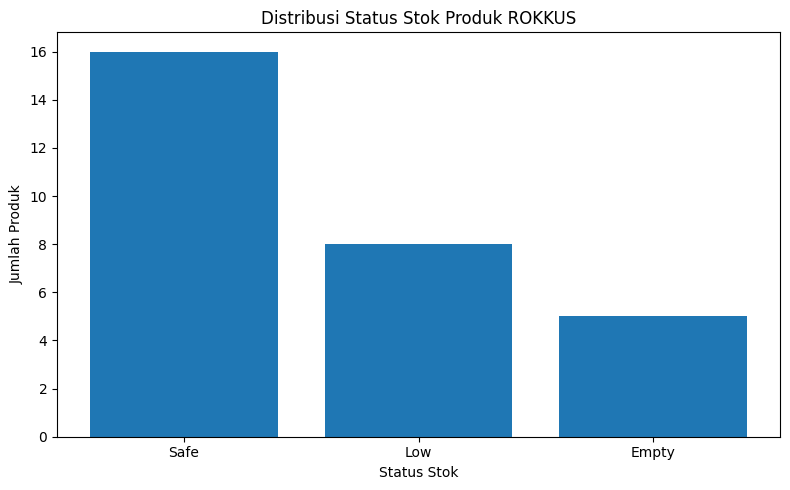

In [34]:
import matplotlib.pyplot as plt

status_counts = df_ringkasan_stok["status_stok"].value_counts()

plt.figure(figsize=(8, 5))
plt.bar(status_counts.index, status_counts.values)

plt.title("Distribusi Status Stok Produk ROKKUS")
plt.xlabel("Status Stok")
plt.ylabel("Jumlah Produk")

plt.tight_layout()

plt.savefig(
    "outputs/grafik_distribusi_status.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

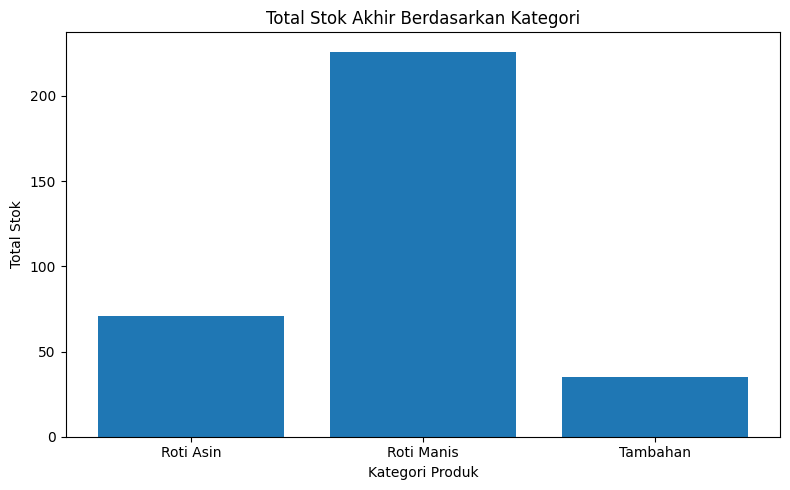

In [35]:
import matplotlib.pyplot as plt

ringkasan_kategori = (
    df_ringkasan_stok
    .groupby("category", as_index=False)["stok_akhir"]
    .sum()
)

plt.figure(figsize=(8, 5))

plt.bar(
    ringkasan_kategori["category"],
    ringkasan_kategori["stok_akhir"]
)

plt.title("Total Stok Akhir Berdasarkan Kategori")
plt.xlabel("Kategori Produk")
plt.ylabel("Total Stok")

plt.tight_layout()

plt.savefig(
    "outputs/grafik_stok_per_kategori.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

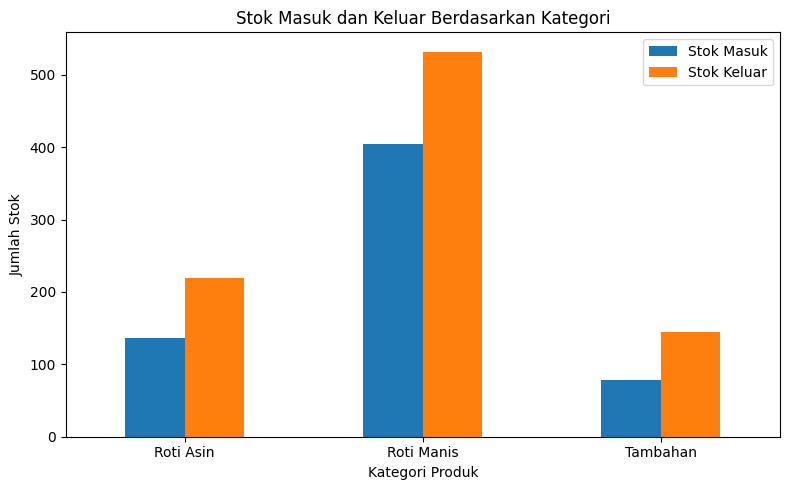

In [36]:
import matplotlib.pyplot as plt

ringkasan_pergerakan = (
    df_ringkasan_stok
    .groupby("category")[["total_masuk", "total_keluar"]]
    .sum()
)

ringkasan_pergerakan.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Stok Masuk dan Keluar Berdasarkan Kategori")
plt.xlabel("Kategori Produk")
plt.ylabel("Jumlah Stok")
plt.xticks(rotation=0)
plt.legend(["Stok Masuk", "Stok Keluar"])

plt.tight_layout()

plt.savefig(
    "outputs/grafik_stok_masuk_keluar.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## 7. Evaluasi Klasifikasi dan Ringkasan Dashboard

Memeriksa konsistensi stok akhir dan status klasifikasi, kemudian menyusun satu file ringkasan dashboard sebagai sumber data ringkas untuk integrasi.

In [37]:
# Menghitung ulang stok akhir
stok_hitung_ulang = (
    df_ringkasan_stok["stok_awal"]
    + df_ringkasan_stok["total_masuk"]
    - df_ringkasan_stok["total_keluar"]
)

# Membandingkan dengan stok akhir yang sudah dihitung
hasil_pemeriksaan = (
    stok_hitung_ulang == df_ringkasan_stok["stok_akhir"]
)

print("Jumlah perhitungan benar:", hasil_pemeriksaan.sum())
print("Jumlah perhitungan tidak sesuai:", (~hasil_pemeriksaan).sum())


Jumlah perhitungan benar: 29
Jumlah perhitungan tidak sesuai: 0


In [38]:
dashboard_summary = pd.DataFrame([{
    "total_produk": len(df_ringkasan_stok),
    "total_stok": df_ringkasan_stok["stok_akhir"].sum(),
    "total_stok_masuk": df_ringkasan_stok["total_masuk"].sum(),
    "total_stok_keluar": df_ringkasan_stok["total_keluar"].sum(),
    "produk_safe": (df_ringkasan_stok["status_stok"] == "Safe").sum(),
    "produk_low": (df_ringkasan_stok["status_stok"] == "Low").sum(),
    "produk_empty": (df_ringkasan_stok["status_stok"] == "Empty").sum()
}])

os.makedirs("outputs", exist_ok=True)

dashboard_summary.to_csv(
    "outputs/dashboard_summary_rokkus.csv",
    index=False
)

display(dashboard_summary)

,total_produk,total_stok,total_stok_masuk,total_stok_keluar,produk_safe,produk_low,produk_empty
0,29,332,620,896,16,8,5


In [39]:
os.makedirs("data/processed", exist_ok=True)

df_ringkasan_stok.to_csv(
    "data/processed/dataset_stok_rokkus_final.csv",
    index=False
)

df_ringkasan_stok[
    ["product_id", "product_name", "category", "stok_akhir", "status_stok"]
].to_csv(
    "data/processed/hasil_klasifikasi_stok_rokkus.csv",
    index=False
)

print("Dataset final dan hasil klasifikasi berhasil disimpan.")

Dataset final dan hasil klasifikasi berhasil disimpan.


## 8. Pengujian Fungsional Otomatis

Lima pengujian dilakukan untuk memastikan perhitungan stok, klasifikasi, batas klasifikasi, validasi stok negatif, dan konsistensi dashboard. Hasil disimpan ke `outputs/hasil_pengujian_fungsional.csv`.

In [40]:
# PENGUJIAN FUNGSIONAL OTOMATIS

hasil_pengujian = []

# TEST 1: Perhitungan stok akhir
stok_seharusnya = (
    df_ringkasan_stok["stok_awal"]
    + df_ringkasan_stok["total_masuk"]
    - df_ringkasan_stok["total_keluar"]
)

test_stok = (
    stok_seharusnya == df_ringkasan_stok["stok_akhir"]
).all()

hasil_pengujian.append({
    "No": 1,
    "Pengujian": "Perhitungan stok akhir",
    "Hasil yang Diharapkan": "29 data sesuai",
    "Status": "PASS" if test_stok else "FAIL"
})

# TEST 2: Klasifikasi status stok
hasil_klasifikasi = df_ringkasan_stok["stok_akhir"].apply(
    klasifikasi_stok
)

test_klasifikasi = (
    hasil_klasifikasi == df_ringkasan_stok["status_stok"]
).all()

hasil_pengujian.append({
    "No": 2,
    "Pengujian": "Klasifikasi status stok",
    "Hasil yang Diharapkan": "29 data sesuai",
    "Status": "PASS" if test_klasifikasi else "FAIL"
})

# TEST 3: Batas klasifikasi
data_uji = {
    0: "Empty",
    1: "Low",
    5: "Low",
    6: "Safe",
    10: "Safe"
}

test_batas = all(
    klasifikasi_stok(stok) == status
    for stok, status in data_uji.items()
)

hasil_pengujian.append({
    "No": 3,
    "Pengujian": "Batas klasifikasi",
    "Hasil yang Diharapkan": "Seluruh batas sesuai",
    "Status": "PASS" if test_batas else "FAIL"
})

# TEST 4: Validasi stok negatif berdasarkan urutan transaksi
test_stok_negatif = (
    df_riwayat_stok["stok_setelah_transaksi"] >= 0
).all()

hasil_pengujian.append({
    "No": 4,
    "Pengujian": "Validasi stok negatif",
    "Hasil yang Diharapkan": "0 stok negatif",
    "Status": "PASS" if test_stok_negatif else "FAIL"
})

# TEST 5: Konsistensi dashboard
test_dashboard = (
    dashboard_summary.loc[0, "total_produk"]
    == len(df_ringkasan_stok)
    and dashboard_summary.loc[0, "total_stok"]
    == df_ringkasan_stok["stok_akhir"].sum()
    and dashboard_summary.loc[0, "total_stok_masuk"]
    == df_ringkasan_stok["total_masuk"].sum()
    and dashboard_summary.loc[0, "total_stok_keluar"]
    == df_ringkasan_stok["total_keluar"].sum()
    and dashboard_summary.loc[0, "produk_safe"]
    == (df_ringkasan_stok["status_stok"] == "Safe").sum()
    and dashboard_summary.loc[0, "produk_low"]
    == (df_ringkasan_stok["status_stok"] == "Low").sum()
    and dashboard_summary.loc[0, "produk_empty"]
    == (df_ringkasan_stok["status_stok"] == "Empty").sum()
)

hasil_pengujian.append({
    "No": 5,
    "Pengujian": "Ringkasan dashboard",
    "Hasil yang Diharapkan": "Ringkasan konsisten",
    "Status": "PASS" if test_dashboard else "FAIL"
})

# Membuat tabel hasil pengujian
hasil_pengujian = pd.DataFrame(hasil_pengujian)

display(hasil_pengujian)

# Menyimpan hasil pengujian
os.makedirs("outputs", exist_ok=True)

hasil_pengujian.to_csv(
    "outputs/hasil_pengujian_fungsional.csv",
    index=False
)

print("Jumlah PASS:",
      (hasil_pengujian["Status"] == "PASS").sum())

print("Jumlah FAIL:",
      (hasil_pengujian["Status"] == "FAIL").sum())

print("Pengujian selesai!")

,No,Pengujian,Hasil yang Diharapkan,Status
0,1,Perhitungan stok akhir,29 data sesuai,PASS
1,2,Klasifikasi status stok,29 data sesuai,PASS
2,3,Batas klasifikasi,Seluruh batas sesuai,PASS
3,4,Validasi stok negatif,0 stok negatif,PASS
4,5,Ringkasan dashboard,Ringkasan konsisten,PASS


Jumlah PASS: 5
Jumlah FAIL: 0
Pengujian selesai!


## 9. Verifikasi Kelengkapan File dan Pembuatan ZIP

Satu pemeriksaan akhir memastikan seluruh file utama tersedia. Arsip ZIP berisi folder `data/` dan `outputs/` untuk memudahkan pengunduhan.

In [41]:
from pathlib import Path
import zipfile

daftar_file = [
    "data/raw/master_produk_rokkus.csv",
    "data/raw/stok_awal.csv",
    "data/raw/transaksi_stok.csv",
    "data/processed/dataset_stok_rokkus_final.csv",
    "data/processed/hasil_klasifikasi_stok_rokkus.csv",
    "outputs/dashboard_summary_rokkus.csv",
    "outputs/grafik_distribusi_status.png",
    "outputs/grafik_stok_per_kategori.png",
    "outputs/grafik_stok_masuk_keluar.png",
    "outputs/hasil_pengujian_fungsional.csv",
]

print("VERIFIKASI FILE PROYEK")
status_file = []
for nama in daftar_file:
    tersedia = Path(nama).exists()
    status_file.append({
        "file": nama,
        "status": "TERSEDIA" if tersedia else "BELUM ADA"
    })
    print(("TERSEDIA: " if tersedia else "BELUM ADA: ") + nama)

display(pd.DataFrame(status_file))

file_belum_ada = [nama for nama in daftar_file if not Path(nama).exists()]

if not file_belum_ada:
    with zipfile.ZipFile(
        "ROKKUS_Data_Preparation_Outputs.zip",
        "w",
        compression=zipfile.ZIP_DEFLATED
    ) as zf:
        for nama in daftar_file:
            zf.write(nama, arcname=nama)

    print("ZIP berhasil dibuat dan mencakup folder data/ serta outputs/.")
else:
    print("ZIP belum dibuat. File berikut belum tersedia:")
    for nama in file_belum_ada:
        print("-", nama)


VERIFIKASI FILE PROYEK
TERSEDIA: data/raw/master_produk_rokkus.csv
TERSEDIA: data/raw/stok_awal.csv
TERSEDIA: data/raw/transaksi_stok.csv
TERSEDIA: data/processed/dataset_stok_rokkus_final.csv
TERSEDIA: data/processed/hasil_klasifikasi_stok_rokkus.csv
TERSEDIA: outputs/dashboard_summary_rokkus.csv
TERSEDIA: outputs/grafik_distribusi_status.png
TERSEDIA: outputs/grafik_stok_per_kategori.png
TERSEDIA: outputs/grafik_stok_masuk_keluar.png
TERSEDIA: outputs/hasil_pengujian_fungsional.csv


,file,status
0,data/raw/master_produk_rokkus.csv,TERSEDIA
1,data/raw/stok_awal.csv,TERSEDIA
2,data/raw/transaksi_stok.csv,TERSEDIA
3,data/processed/dataset_stok_rokkus_final.csv,TERSEDIA
4,data/processed/hasil_klasifikasi_stok_rokkus.csv,TERSEDIA
5,outputs/dashboard_summary_rokkus.csv,TERSEDIA
6,outputs/grafik_distribusi_status.png,TERSEDIA
7,outputs/grafik_stok_per_kategori.png,TERSEDIA
8,outputs/grafik_stok_masuk_keluar.png,TERSEDIA
9,outputs/hasil_pengujian_fungsional.csv,TERSEDIA


ZIP berhasil dibuat dan mencakup folder data/ serta outputs/.


## 10. Kesimpulan Pengolahan Data Science

Pengolahan data dilakukan menggunakan dataset sintetis yang disusun berdasarkan daftar produk UMKM ROKKUS Mardani Raya. Tahapan meliputi pembuatan master data, simulasi stok awal dan transaksi, pemeriksaan kualitas data, preprocessing, perhitungan stok akhir, EDA, klasifikasi status stok, pembuatan ringkasan dashboard, dan pengujian fungsional.

Hasil akhir digunakan sebagai data simulasi untuk mendukung pengembangan dan pengujian sistem pengelolaan stok. Data ini bukan catatan transaksi aktual UMKM. Nilai stok dan aturan klasifikasi perlu disesuaikan kembali apabila UMKM menyediakan data operasional yang telah diverifikasi.